#Activity 1: Introduction to Regression with Auto MPG

#### participants:
- Gam Twe He
- Sandip Ranjit
- Olga Chitembo

### Question 1: Identify the Machine-Learning Problem


Consider the problem:

We know characteristics of a car and want to predict its fuel efficiency.

Answer:

##### Is this supervised or unsupervised learning?
- This is supervised Learning
##### Is it classification or regression?
- This is regression because we want to predict the actual number.
##### What is the target?
- The target is mpg.
##### Give two possible features.
Possible feature include:
- weight
- horsepower
- displacement
- cylinders



In [ ]:
!pip install -q ucimlrepo scikit-learn pandas matplotlib

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

In [ ]:
auto_mpg = fetch_ucirepo(id=9)

X_full = auto_mpg.data.features
y_full = auto_mpg.data.targets

In [ ]:
X_full.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


In [ ]:
y_full.head()

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0


In [ ]:
print(auto_mpg.metadata)

{'uci_id': 9, 'name': 'Auto MPG', 'repository_url': 'https://archive.ics.uci.edu/dataset/9/auto+mpg', 'data_url': 'https://archive.ics.uci.edu/static/public/9/data.csv', 'abstract': 'Revised from CMU StatLib library, data concerns city-cycle fuel consumption', 'area': 'Other', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 398, 'num_features': 7, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['mpg'], 'index_col': ['car_name'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1993, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5859H', 'creators': ['R. Quinlan'], 'intro_paper': None, 'additional_info': {'summary': 'This dataset is a slightly modified version of the dataset provided in the StatLib library.  In line with the use by Ross Quinlan (1993) in predicting the attribute "mpg", 8 of the original instances were removed because they had unknown values for th

In [ ]:
print(auto_mpg.variables)

           name     role         type demographic description units  \
0  displacement  Feature   Continuous        None        None  None   
1           mpg   Target   Continuous        None        None  None   
2     cylinders  Feature      Integer        None        None  None   
3    horsepower  Feature   Continuous        None        None  None   
4        weight  Feature   Continuous        None        None  None   
5  acceleration  Feature   Continuous        None        None  None   
6    model_year  Feature      Integer        None        None  None   
7        origin  Feature      Integer        None        None  None   
8      car_name       ID  Categorical        None        None  None   

  missing_values  
0             no  
1             no  
2             no  
3            yes  
4             no  
5             no  
6             no  
7             no  
8             no  


### Question 2: Explore the Dataset

#### Answer:

##### Approximately how many observations are there?
- There are 398 observations.
##### Which variable is the target?
- mpg is the target.
##### Which variables are numerical?
 - Feature (displacement, cylinders, horsepower, weight, acceleartion, model_year and origin) are numerical feature.
##### Does any feature contain missing values?
- Feature horsepower contain 6 nulls.
##### Which feature would be a reasonable candidate for predicting mpg?
- For the introductory activity, weight is a useful feature because it is numerical and has a natural relationship with fuel efficiency.



In [ ]:
X_full.isnull().sum()

,0
displacement,0
cylinders,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0


In [ ]:
X_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
dtypes: float64(3), int64(4)
memory usage: 21.9 KB


In [ ]:
X_full.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [ ]:
X = X_full[["weight"]]
y = y_full["mpg"]

###  Question 3: Why Use weight?

As vehicle weight increases, fuel efficiency generally decreases. Therefore, heavier cars tend to have lower MPG.

In statistical language, we would expect a negative association between weight and mpg.



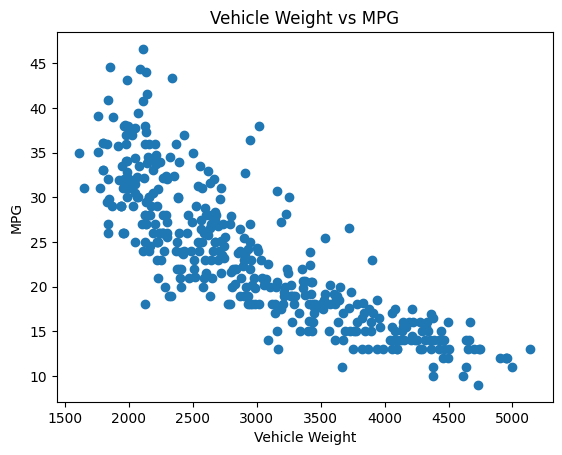

In [ ]:
plt.scatter(X["weight"], y)

plt.xlabel("Vehicle Weight")
plt.ylabel("MPG")
plt.title("Vehicle Weight vs MPG")

plt.show()

### Question 4: Read the Scatter Plot
Look at the scatter plot and answer:

#### Does the relationship appear positive or negative?
- The relationship appears negative.
#### Does it appear approximately linear?
- It appears approximately linear, although there is substantial variation.
#### Are all points exactly on one line?
- No. Real-world observations do not normally lie exactly on one line.
#### Why might there be variation around the general trend?
- Other factors affect fuel efficiency, such as engine characteristics, aerodynamics, transmission, model year, and other vehicle properties.

In [ ]:
correlation = X["weight"].corr(y)

print("Pearson correlation:", correlation)

Pearson correlation: -0.8317409332443352


In [ ]:
df_temp = pd.DataFrame({
    "weight": X["weight"],
    "mpg": y
})

print(df_temp.corr())

          weight       mpg
weight  1.000000 -0.831741
mpg    -0.831741  1.000000


### Question 5: Interpret Pearson r


Suppose the correlation is:

`r = -0.83`

#### Answer:
#### What does the negative sign mean?
- The negative sign indicates a negative linear relationship. Larger vehicle weight tends to be associated with lower MPG.
#### What does the magnitude tell you?
- The magnitude, 0.83, indicates a strong linear association.
#### Does r = -0.83 prove that weight causes MPG to decrease?
- No. Correlation measures association and does not prove causation.
#### Does it mean that every heavy car has lower MPG than every light car?
- No. Correlation describes the overall pattern. Individual observations can still differ substantially.


### Question 6: Pearson Limitation
Consider:

` x = [-3, -2, -1, 0, 1, 2, 3]`

`y = [9, 4, 1, 0, 1, 4, 9]`

Answer:

1. Is there a relationship?
- Yes. There is a perfect mathematical relationship: y = x^2
2. Is it linear?
- It is nonlinear.
3. Would Pearson correlation necessarily identify it as a strong relationship?
- No. Pearson correlation measures linear association, and the correlation for this symmetric example is zero.
4. Why?
- The positive and negative values of x produce the same positive y values. Their linear effects cancel out.

In [ ]:
model = LinearRegression()

In [ ]:
model.fit(X, y)

LinearRegression()

In [ ]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 46.31736442026563
Coefficient: -0.007676610063926465


### Question 7: Interpret the Coefficient

Answer:

1. What does the negative sign mean?
- The negative sign means that increasing vehicle weight is associated with decreasing predicted MPG.
2. What does the magnitude of the coefficient mean?
- The magnitude describes how much the model's predicted MPG changes for a one-unit increase in weight.
3. Why should the coefficient be interpreted in terms of the units of the feature?
- Regression coefficients depend on the units used by the features. Changing from pounds to kilograms, for example, would change the numerical value of the coefficient.
4. Does a negative coefficient mean the model is wrong?
- No. A negative coefficient makes sense because heavier vehicles generally have lower fuel efficiency in this dataset.

In [ ]:
predictions = model.predict(X)

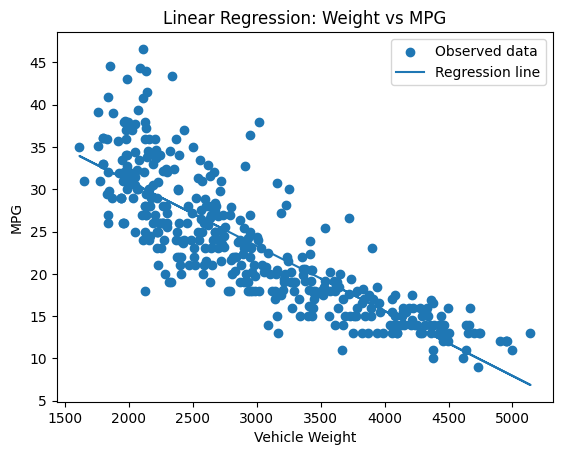

In [ ]:
plt.scatter(X["weight"], y, label="Observed data")
plt.plot(X["weight"], predictions, label="Regression line")

plt.xlabel("Vehicle Weight")
plt.ylabel("MPG")
plt.title("Linear Regression: Weight vs MPG")

plt.legend()
plt.show()

### Question 8: Understand the Regression Line
Answer:

1. What do the individual points represent?
- One training sample.
2. What does the line represent?
- The linear regression model for this dataset.
3. Why does the line not pass through every point?
- Real-world data contain variation. Vehicle weight is not the only factor affecting fuel efficiency.
4. Why can the line still be useful even though it does not perfectly describe every car?
- The regression line summarizes the overall relationship and can be used to make predictions for new observations.

In [ ]:
new_car = [[3000]]

prediction = model.predict(new_car)

print("Predicted MPG:", prediction[0])

Predicted MPG: 23.287534228486237


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
predicted_mpg = prediction[0]

predicted_km_per_liter = predicted_mpg * 0.425

print("Predicted MPG:", predicted_mpg)
print("Approximate km/L:", predicted_km_per_liter)

Predicted MPG: 23.287534228486237
Approximate km/L: 9.897202047106651


### Question 9: Prediction

Suppose the model predicts:

30 MPG

Answer:

1. What does this prediction mean?
- The model estimates that a car with the given weight has fuel efficiency of approximately 30 miles per US gallon.
2. Approximately how many km/L is this?
- Approximately: 30 * 0.425 equal to 12.75 km/l
3. Does this mean that every 3000-unit-weight car gets exactly 30 MPG?
- No. The model provides an estimate based on the learned relationship.
4. Is the prediction guaranteed to be correct?
- No. Real observations contain variation and the model does not know every factor affecting the actual fuel efficiency.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### Question 10: Understand the Split

Answer:

1. What percentage of the observations is approximately used for testing?
- Approximately 20 % is used for testing.
2. Which data should be used to train the model?
- X_train and Y_train
3. Which data should be used for final evaluation?
- X_test and Y_test
4. Why should the test data not be used for training?
- The test data should represent unseen observations. If it is used during training, it is no longer an independent test of generalization.
5. What is the purpose of random_state=42?
- It makes the randomized split reproducible.

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 3.1177861992064573


In [ ]:
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

print("RMSE:", rmse)

RMSE: 3.8593860994510765


In [ ]:
r2 = r2_score(y_test, y_pred)

print("R²:", r2)

R²: 0.722971057303075


### Question 11: Interpret the Metrics

Suppose the model produces:

- ` MAE  = 2.4`
- ` RMSE = 3.3`
- ` R²   = 0.65`

Answer:

1. What does MAE tell us?
- MAE indicates that the average absolute prediction error is about 2.4 MPG.
2. What does RMSE tell us?
- RMSE summarizes prediction error while giving larger errors greater influence.
3. Why is RMSE greater than MAE in this example?
- RMSE is often larger than MAE because squaring the errors gives more weight to large errors.
4. What does R² tell us?
- R² indicates how well the model explains variation in the target relative to the reference baseline.
5. Why should we not call R² "65% accuracy"?
- Accuracy is a classification metric. R² is a regression metric and does not mean that 65% of predictions are "correct."


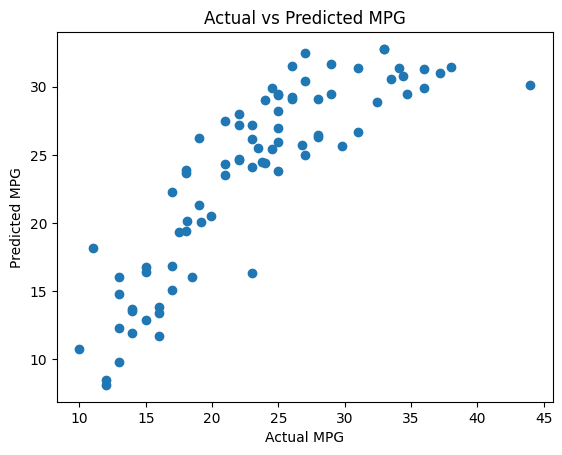

In [ ]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")

plt.show()

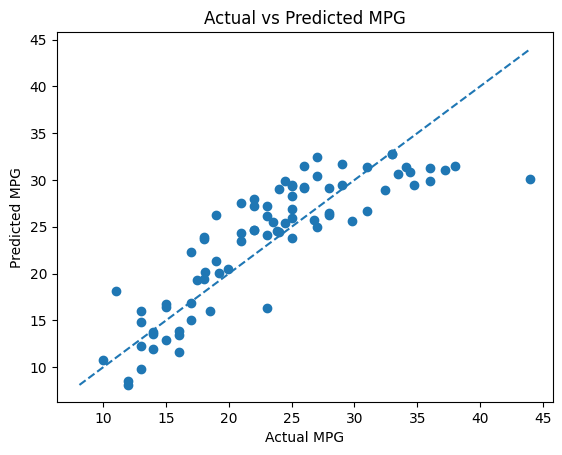

In [ ]:
plt.scatter(y_test, y_pred)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")

plt.show()

### Question 12: Interpret the Prediction Plot

Answer:


1.   What would a point exactly on the diagonal mean?
- A point on the diagonal means the prediction equals the actual value.
2.   What does a point far from the diagonal mean?
- A point far from the diagonal represents a larger prediction error.
3.   Would you expect all points to lie exactly on the diagonal?
- No. Real-world predictions are rarely perfect.
4.   What does a cluster of points around the diagonal suggest?
- A cluster of points close to the diagonal suggests that the predictions are generally close to the actual values.



In [ ]:
X = X_full[
    [
        "cylinders",
        "displacement",
        "weight"
    ]
]

y = y_full["mpg"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 3.1092532313465484
RMSE: 3.8661967069009027
R²: 0.7219924560018649


In [ ]:
print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 44.31685291951133
cylinders : -0.10181468483226533
displacement : -0.016942167127717435
weight : -0.005693627208100814


### Question 13: Simple vs Multiple Linear Regression


| Model | Number of Features | Example |
| :--- | :--- | :--- |
| Simple Linear Regression | One | `weight` → `mpg` |
| Multiple Linear Regression | Two or more | `weight` + `displacement` + `cylinders` → `mpg` |


Then answer:

1. Why might multiple regression perform better than simple regression?
- Multiple regression can use information from several characteristics of the car.
2. Does adding more features always improve the model?
- No. Additional features can be irrelevant, noisy, redundant, or introduce other modeling problems.
3. Why might some features be unhelpful?
- Some features may contain little useful information for the target or may overlap strongly with other features.

In [ ]:
mae_simple = mean_absolute_error(y_test, y_pred)

In [ ]:
# Simple regression
X_simple = X_full[["weight"]]
y_simple = y_full["mpg"]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)

y_pred_simple = simple_model.predict(X_test_simple)

mae_simple = mean_absolute_error(y_test_simple, y_pred_simple)

rmse_simple = np.sqrt(
    mean_squared_error(y_test_simple, y_pred_simple)
)

r2_simple = r2_score(y_test_simple, y_pred_simple)

print("Simple Regression")
print("MAE:", mae_simple)
print("RMSE:", rmse_simple)
print("R²:", r2_simple)

Simple Regression
MAE: 3.1177861992064573
RMSE: 3.8593860994510765
R²: 0.722971057303075


In [ ]:
X_multiple = X_full[
    [
        "cylinders",
        "displacement",
        "weight"
    ]
]

y_multiple = y_full["mpg"]

X_train_multiple, X_test_multiple, y_train_multiple, y_test_multiple = train_test_split(
    X_multiple,
    y_multiple,
    test_size=0.2,
    random_state=42
)

multiple_model = LinearRegression()

multiple_model.fit(
    X_train_multiple,
    y_train_multiple
)

y_pred_multiple = multiple_model.predict(X_test_multiple)

mae_multiple = mean_absolute_error(
    y_test_multiple,
    y_pred_multiple
)

rmse_multiple = np.sqrt(
    mean_squared_error(
        y_test_multiple,
        y_pred_multiple
    )
)

r2_multiple = r2_score(
    y_test_multiple,
    y_pred_multiple
)

print("Multiple Regression")
print("MAE:", mae_multiple)
print("RMSE:", rmse_multiple)
print("R²:", r2_multiple)

Multiple Regression
MAE: 3.1092532313465484
RMSE: 3.8661967069009027
R²: 0.7219924560018649


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MAE": [
        mae_simple,
        mae
    ],
    "RMSE": [
        rmse_simple,
        rmse
    ],
    "R2": [
        r2_simple,
        r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Simple Linear Regression,3.117786,3.859386,0.722971
1,Multiple Linear Regression,3.109253,3.866197,0.721992


### Question 14: Compare the Models

1. Which model has the lower MAE?
- The model with the lower MAE has smaller average absolute prediction error.
2. Which model has the lower RMSE?
- The model with the lower RMSE has lower prediction error while giving greater influence to large errors.
3. Which model has the higher R²?
- The model with the higher R² explains more variation relative to the metric's reference baseline.
4. Does the multiple-feature model perform better?
- The test results determine whether the additional features improved generalization.
5. Is a model automatically better simply because it has more features?
- No. Adding features does not automatically guarantee better performance on unseen data.



In [ ]:
train_predictions = multiple_model.predict(
    X_train_multiple
)

test_predictions = multiple_model.predict(
    X_test_multiple
)

In [ ]:
train_rmse = np.sqrt(
    mean_squared_error(
        y_train_multiple,
        train_predictions
    )
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_multiple,
        test_predictions
    )
)

print("Training RMSE:", train_rmse)
print("Test RMSE:", test_rmse)

Training RMSE: 4.392137000192713
Test RMSE: 3.8661967069009027


### Question 15: Interpret Training vs Test Error

- Training RMSE = 2.0
- Test RMSE     = 8.0

Answer:

1. Is the model performing better on training or test data?
- The model performs better on the training data.
2. Is the difference concerning?
- The large difference is a warning sign that the model may not generalize well.
3. What machine-learning concept might this indicate?
- It may indicate overfitting.
4. Why is test performance important?
- Test performance gives information about how the model performs on observations it did not use during training.


### Question 16: What is regression?
- Regression is a supervised machine-learning approach used to predict a numerical target from one or more input features.

### Question 17: What is the difference between a feature and a target?
- A feature is an input variable used by the model to make a prediction.

- The target is the variable the model is trying to predict.





### Question 18: What does Pearson correlation tell us?
Pearson correlation describes the strength and direction of a linear relationship between two numerical variables.

Its value ranges from:

−
1
≤
r
≤
1

The sign indicates the direction, while the magnitude indicates the strength of the linear association.

Its important limitation is that it measures linear association. A strong nonlinear relationship can have a Pearson correlation close to zero.



### Question 19: Why is r = 0 not proof that two variables have no relationship?

For example:

y = x^2

can produce:

r = 0

for a symmetric dataset such as:

```python
x = [-3,-2,-1,0,1,2,3]
y = [ 9, 4, 1,0,1,4,9]
```

There is a perfect nonlinear relationship, but there is no linear trend.



### Question 20: What does fit() do?
fit() trains the model using the training features and their known target values. For linear regression, it estimates the coefficients and intercept that define the fitted regression model.

### Question 21: What does predict() do?

`fit()` learns the model from known training examples.

`predict()` uses the trained model to estimate the target for new observations.

For example:

```python
model.fit(X_train, y_train)
```
learns the relationship.

Then:

```python
model.predict(X_test)
```
produces predicted MPG values for the test cars.


### Question 23: What is the difference between simple and multiple linear regression?

Simple linear regression uses one feature and multiple linear regression uses multiple features.


### Question 24: Why should a model not automatically be judged by its training error?

A low training error alone may indicate that the model fits the training data very well, but it does not tell us whether the model generalizes.

A model with slightly higher training error but much lower test error may be more useful for predicting new observations.

This is related to overfitting.



# Final Answers

### Q1: What type of machine-learning problem is Auto MPG?
It is a supervised regression problem because the target `mpg` is a numerical value.

### Q2: What is the target variable?
The target is: `mpg`

### Q3: What does MPG mean?
MPG means miles per gallon and represents how many miles a vehicle can travel using one US gallon of fuel.

### Q4: How can MPG be converted to km/L?
Approximately:

$$\text{km/L} \approx \text{MPG} \times 0.425$$

For example:

$$30 \text{ MPG} \approx 12.75 \text{ km/L}$$

### Q5: What does Pearson r measure?
Pearson $r$ measures the strength and direction of a linear relationship between two numerical variables.

### Q6: What does a negative Pearson correlation mean?
It means that larger values of one variable tend to be associated with smaller values of the other variable in a linear relationship.

### Q7: Why can r be close to zero when a relationship exists?
Because Pearson measures linear association. A strong nonlinear relationship such as $y = x^2$ can have a Pearson correlation close to zero.

### Q8: What is the purpose of LinearRegression()?
It creates a scikit-learn linear regression model that can be trained to predict a numerical target.

### Q9: What does fit() do?
It learns the model parameters from the training data.

### Q10: What does predict() do?
It uses the trained model to produce predictions for new observations.

### Q11: Why use a train/test split?
To evaluate the model on observations that were not used during training and therefore obtain an estimate of generalization performance.

### Q12: What does MAE measure?
MAE measures the average absolute prediction error.

### Q13: What does RMSE measure?
RMSE summarizes prediction error while giving larger errors more influence. It is expressed in the same units as the target.

### Q14: What does R² tell us?
$R^2$ describes how much variation in the target is explained by the model relative to the metric's reference baseline.

### Q15: Simple vs multiple linear regression?
* **Simple linear regression** uses one feature.
* **Multiple linear regression** uses two or more features.

### Q16: What is underfitting?
Underfitting occurs when the model is too simple to capture important patterns in the data. Training and test performance are often both poor.

### Q17: What is overfitting?
*(Note: Definition missing from source text)*

### Q18: Why is test performance important?
Because the ultimate goal of a machine-learning model is to make useful predictions on new observations, not merely to fit the training data.
